# PathSnap: Dataset Exploration (EDA)

**Partitions used:** `train` (80 trips) and `student_test` (10 trips). The partition is stated for every analysis below.
The `evaluator_test` partition is **never** loaded in this notebook.

Outputs written by this notebook:
- tables: `experiments/results/eda/*.csv`
- figures: `reports/figures/eda/*.png`
- interactive maps: `reports/maps/eda_*.html`

Sections:
1. Raw file format
2. Dataset inventory
3. Missing-value and invalid-observation analysis
4. Timestamps and sampling gaps
5. Geographic extent
6. Trajectory patterns
7. Road network size and connectivity
8. Reference routes
9. GPS observations vs. reference route
10. Anomalous trips
11. Folium maps
12. Key findings and decisions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

from pathsnap.config import DEV_PARTITIONS, FIGURES_DIR, MAPS_DIR, RESULTS_DIR, STUDENT_TEST, TRAIN
from pathsnap.io import list_trips, load_trip, trip_dir
from pathsnap.geo import arc_table, project_trip
from pathsnap.labels import align_route
from pathsnap.candidates import generate_candidates
from pathsnap.viz import trip_map

EDA_DIR = RESULTS_DIR / "eda"
EDA_FIG = FIGURES_DIR / "eda"
for d in (EDA_DIR, EDA_FIG, MAPS_DIR):
    d.mkdir(parents=True, exist_ok=True)

assert set(DEV_PARTITIONS) == {TRAIN, STUDENT_TEST}  # evaluator partition is never touched here
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200, "display.max_columns", 40)

def savefig(name):
    plt.savefig(EDA_FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Raw file format
**Partition:** train (trip `00000001`, as an example).

We read the raw bytes to see the exact separators and line endings, without assuming a format.

In [2]:
d = trip_dir("00000001")
for ext in ["track", "nodes", "arcs", "route"]:
    with open(d / f"00000001.{ext}", "rb") as f:
        print(f"{ext:6s}", [f.readline() for _ in range(3)])

track  [b'8.595203\t49.844053\t1.000000\r\n', b'8.595294\t49.844441\t2.000000\r\n', b'8.595352\t49.844883\t3.000000\r\n']
nodes  [b'8.581679\t49.857880\n', b'8.584637\t49.858295\n', b'8.580173\t49.858567\n']
arcs   [b'0\t281\n', b'0\t1\n', b'0\t5\n']
route  [b'2641\n', b'64973\n', b'133948\n']


- No header row in any file. Columns are **tab-separated**.
- `.track` lines end in `\r\n` (Windows); the other files end in `\n`. `pd.read_csv(sep=r"\s+")` handles both.
- `.track` = `lon lat t`, `.nodes` = `lon lat`, `.arcs` = `from_node to_node`, `.route` = `arc_id`.
  **Longitude comes first**, so every map must flip to `[lat, lon]`.
- `node_id` and `arc_id` are implicit **0-based row indices**. The row number *is* the id.

In [3]:
trip = load_trip("00000001", with_route=True)
for name, df in [("track", trip.track), ("nodes", trip.nodes), ("arcs", trip.arcs)]:
    print(f"--- {name}: shape {df.shape}"); print(df.dtypes.to_string()); print(df.head(3).to_string(), "\n")
print("--- route: first arc ids", trip.route[:8], "| length", len(trip.route))

--- track: shape (1315, 3)
lon    float64
lat    float64
t      float64
        lon        lat    t
0  8.595203  49.844053  1.0
1  8.595294  49.844441  2.0
2  8.595352  49.844883  3.0 

--- nodes: shape (88809, 2)
lon    float64
lat    float64
              lon        lat
node_id                     
0        8.581679  49.857880
1        8.584637  49.858295
2        8.580173  49.858567 

--- arcs: shape (165790, 2)
u    int64
v    int64
        u    v
arc_id        
0       0  281
1       0    1
2       0    5 

--- route: first arc ids [2641, 64973, 133948, 133949, 139208, 133950, 8970, 133951] | length 525


## 2. Dataset inventory
**Partitions:** train + student_test (all 90 trips).

One pass over every trip collects file sizes, observation counts, network size, time gaps,
connectivity and route statistics. The route is loaded here **only for analysis**; prediction code never loads it.

In [4]:
JUMP_SPEED_MS = 70.0   # > 252 km/h between consecutive fixes is physically implausible for a car
STATIONARY_STEP_M = 0.5

rows, dts, speeds, label_d, arc_lens, out_degs = [], [], [], [], [], []
for part in DEV_PARTITIONS:
    for tid in list_trips(part):
        d = trip_dir(tid, part)
        r = {"partition": part, "trip_id": tid}
        for ext in ["track", "nodes", "arcs", "route"]:
            f = d / f"{tid}.{ext}"
            r[f"has_{ext}"] = f.exists()
            r[f"{ext}_kb"] = round(f.stat().st_size / 1024, 1) if f.exists() else np.nan

        trip = project_trip(load_trip(tid, part, with_route=True))
        tr, nodes, arcs, route = trip.track, trip.nodes, trip.arcs, np.asarray(trip.route)
        t = tr["t"].to_numpy(); dt = np.diff(t)
        x, y = tr["x"].to_numpy(), tr["y"].to_numpy()
        step = np.hypot(np.diff(x), np.diff(y))
        spd = np.divide(step, dt, out=np.zeros_like(step), where=dt > 0)

        # --- GPS track
        r.update(n_points=len(tr),
                 nan_values=int(tr[["lon", "lat", "t"]].isna().sum().sum()),
                 invalid_coords=int(((tr.lon.abs() > 180) | (tr.lat.abs() > 90) | ((tr.lon == 0) & (tr.lat == 0))).sum()),
                 duplicate_t=int((dt == 0).sum()),
                 non_increasing_t=int((dt < 0).sum()),
                 non_integer_t=int((t % 1 != 0).sum()),
                 duration_min=(t[-1] - t[0]) / 60,
                 pct_dt_1s=100 * (dt == 1).mean(),
                 gaps_gt10s=int((dt > 10).sum()), gaps_gt60s=int((dt > 60).sum()), max_gap_s=dt.max(),
                 missing_seconds_pct=100 * (dt - 1).clip(min=0).sum() / max(t[-1] - t[0], 1),
                 jumps=int((spd > JUMP_SPEED_MS).sum()),
                 stationary_pct=100 * (step < STATIONARY_STEP_M).mean(),
                 path_km=step[dt <= 10].sum() / 1000,
                 bbox_w_km=(x.max() - x.min()) / 1000, bbox_h_km=(y.max() - y.min()) / 1000,
                 lon_c=tr.lon.mean(), lat_c=tr.lat.mean(), crs=trip.crs)

        # --- road network
        u, v = arcs["u"].to_numpy(), arcs["v"].to_numpy()
        n = len(nodes)
        g = coo_matrix((np.ones(len(u)), (u, v)), shape=(n, n)).tocsr()
        n_wcc, wcc = connected_components(g, directed=True, connection="weak")
        n_scc, scc = connected_components(g, directed=True, connection="strong")
        deg = np.bincount(u, minlength=n) + np.bincount(v, minlength=n)
        pairs = set(zip(u.tolist(), v.tolist()))
        geom = arc_table(trip)
        r.update(n_nodes=n, n_arcs=len(arcs),
                 isolated_nodes=int((deg == 0).sum()),
                 self_loops=int((u == v).sum()),
                 duplicate_arcs=int(len(arcs) - len(pairs)),
                 two_way_pct=100 * np.mean([(b, a) in pairs for a, b in zip(u.tolist(), v.tolist())]),
                 zero_length_arcs=int((geom.length_m < 0.01).sum()),
                 median_arc_m=geom.length_m.median(),
                 n_weak_components=n_wcc,
                 largest_wcc_pct=100 * np.bincount(wcc).max() / n,
                 n_strong_components=n_scc,
                 largest_scc_pct=100 * np.bincount(scc).max() / n)

        # --- reference route
        conn = v[route[:-1]] == u[route[1:]]
        big_scc = np.argmax(np.bincount(scc))
        r.update(n_route=len(route), route_unique_arcs=len(set(route.tolist())),
                 route_repeated_arcs=len(route) - len(set(route.tolist())),
                 route_connected_pct=100 * conn.mean(), route_breaks=int((~conn).sum()),
                 route_km=geom.length_m.to_numpy()[route].sum() / 1000,
                 route_in_largest_scc_pct=100 * (scc[u[route]] == big_scc).mean())

        # --- GPS vs route (label alignment) and two-way ties
        lab = align_route(trip)
        cands = generate_candidates(trip, max_k=2)
        tied = cands[cands.dist_rank == 0].groupby("obs_idx").size()
        r.update(median_label_dist_m=lab.label_dist_m.median(), p95_label_dist_m=lab.label_dist_m.quantile(.95),
                 low_conf_pct=100 * lab.low_conf.mean(),
                 nearest_tie_pct=100 * (tied > 1).sum() / len(tr))
        rows.append(r)

        dts.append(pd.DataFrame({"partition": part, "dt": dt}))
        speeds.append(pd.DataFrame({"partition": part, "speed_kmh": 3.6 * spd[(dt > 0) & (dt <= 10)]}))
        label_d.append(pd.DataFrame({"partition": part, "trip_id": tid, "label_dist_m": lab.label_dist_m}))
        arc_lens.append(geom.length_m.sample(min(5000, len(geom)), random_state=42))
        out_degs.append(np.bincount(u, minlength=n))

inv = pd.DataFrame(rows)
dts, speeds, label_d = (pd.concat(x, ignore_index=True) for x in (dts, speeds, label_d))
inv.to_csv(EDA_DIR / "trip_inventory.csv", index=False)
print(inv.shape)

(90, 53)


In [5]:
summary = inv.groupby("partition").agg(
    trips=("trip_id", "size"),
    files_missing=("has_track", lambda s: 0),
    points_total=("n_points", "sum"), points_median=("n_points", "median"),
    points_min=("n_points", "min"), points_max=("n_points", "max"),
    nodes_median=("n_nodes", "median"), arcs_median=("n_arcs", "median"), arcs_max=("n_arcs", "max"),
    route_arcs_median=("n_route", "median"), duration_min_median=("duration_min", "median"),
    path_km_median=("path_km", "median"), size_mb_total=("arcs_kb", lambda s: 0))
summary["files_missing"] = inv.groupby("partition")[[f"has_{e}" for e in ["track", "nodes", "arcs", "route"]]].apply(lambda d: int((~d).sum().sum()))
summary["size_mb_total"] = inv.groupby("partition")[[f"{e}_kb" for e in ["track", "nodes", "arcs", "route"]]].sum().sum(axis=1) / 1024
summary.round(1).to_csv(EDA_DIR / "partition_summary.csv")
summary.round(1).T

partition,student_test,train
trips,10.0,80.0
files_missing,0.0,0.0
points_total,19160.0,208417.0
points_median,1420.0,1529.0
points_min,262.0,361.0
points_max,3958.0,19313.0
nodes_median,6596.5,9608.0
arcs_median,13145.0,19526.5
arcs_max,56027.0,307392.0
route_arcs_median,250.0,280.0


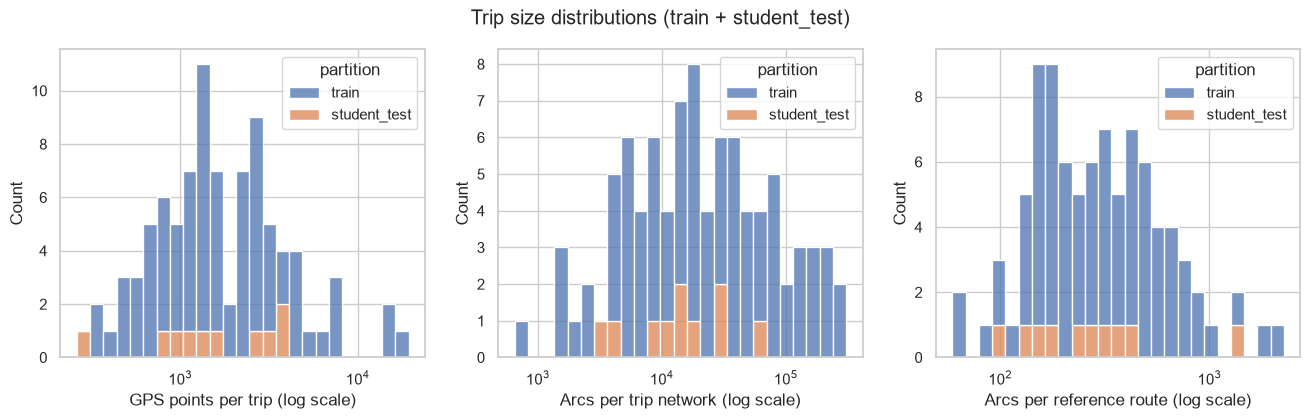

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, label in zip(axes, ["n_points", "n_arcs", "n_route"], ["GPS points per trip", "Arcs per trip network", "Arcs per reference route"]):
    sns.histplot(data=inv, x=col, hue="partition", log_scale=True, bins=25, ax=ax, multiple="stack")
    ax.set_xlabel(label + " (log scale)")
fig.suptitle("Trip size distributions (train + student_test)")
savefig("01_trip_sizes"); plt.show()

## 3. Missing-value and invalid-observation analysis
**Partitions:** train + student_test.

"Missing" has two meanings for GPS data:
1. **Missing or invalid values in the files**: NaNs, impossible coordinates, duplicate or decreasing timestamps.
2. **Missing observations in time**: seconds where the logger recorded nothing. The data is nominally 1 Hz,
   so a 30 s gap means 29 missing fixes.

In [7]:
mv = inv.groupby("partition")[["nan_values", "invalid_coords", "duplicate_t", "non_increasing_t",
                               "non_integer_t", "jumps", "isolated_nodes", "self_loops", "duplicate_arcs",
                               "zero_length_arcs"]].sum()
mv["trips_with_missing_files"] = inv.groupby("partition")[[f"has_{e}" for e in ["track", "nodes", "arcs", "route"]]].apply(lambda d: int((~d.all(axis=1)).sum()))
mv.to_csv(EDA_DIR / "missing_invalid_summary.csv")
mv.T

partition,student_test,train
nan_values,0,0
invalid_coords,0,0
duplicate_t,0,0
non_increasing_t,0,0
non_integer_t,0,9659
jumps,1,150
isolated_nodes,0,0
self_loops,2,22
duplicate_arcs,128,1775
zero_length_arcs,6,100


Trips with non-integer timestamps: ['00000002', '00000071', '00000097']
Trips with implausible jumps (> 252 km/h): [['00000001', 1], ['00000008', 1], ['00000013', 95], ['00000032', 43], ['00000033', 1], ['00000043', 2], ['00000053', 1], ['00000057', 1], ['00000079', 2], ['00000092', 3], ['00000040', 1]]


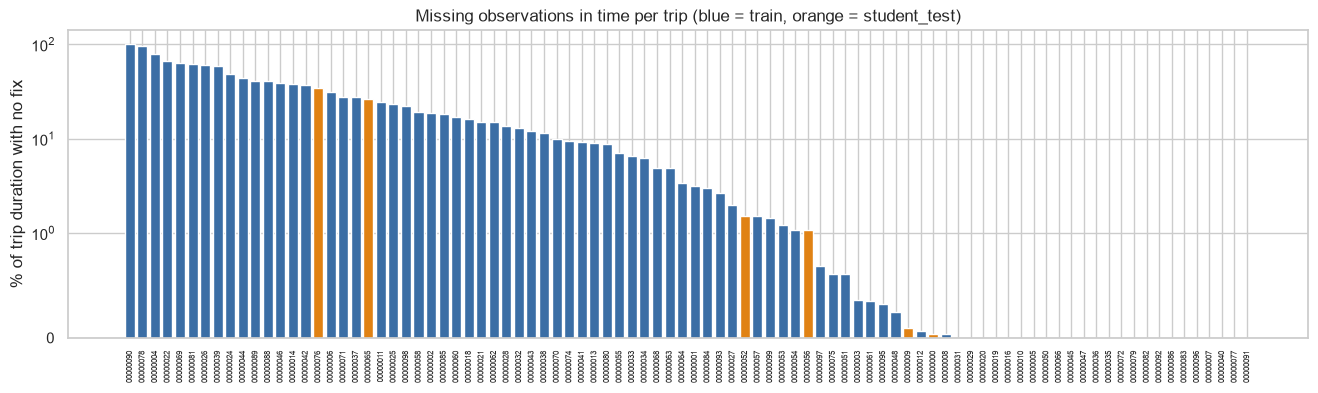

count    90.00
mean     15.13
std      22.58
min       0.00
25%       0.00
50%       3.29
75%      21.62
max      99.65
Name: missing_seconds_pct, dtype: float64

In [8]:
print("Trips with non-integer timestamps:", inv.loc[inv.non_integer_t > 0, "trip_id"].tolist())
print("Trips with implausible jumps (> 252 km/h):", inv.loc[inv.jumps > 0, ["trip_id", "jumps"]].values.tolist())
fig, ax = plt.subplots(figsize=(16, 4))
o = inv.sort_values("missing_seconds_pct", ascending=False)
ax.bar(o.trip_id, o.missing_seconds_pct, color=np.where(o.partition == TRAIN, "#3b6ea5", "#e08214"))
ax.set_yscale("symlog", linthresh=1); ax.set_ylabel("% of trip duration with no fix")
ax.set_title("Missing observations in time per trip (blue = train, orange = student_test)")
ax.tick_params(axis="x", rotation=90, labelsize=6)
savefig("02_missing_seconds_per_trip"); plt.show()
inv.missing_seconds_pct.describe().round(2)

## 4. Timestamps and sampling gaps
**Partitions:** train + student_test.

Timestamps strictly increasing in every trip: True
Share of 1-second steps over all trips: 96.68%
Trips with at least one gap > 10 s: 42 / 90;  > 60 s: 23


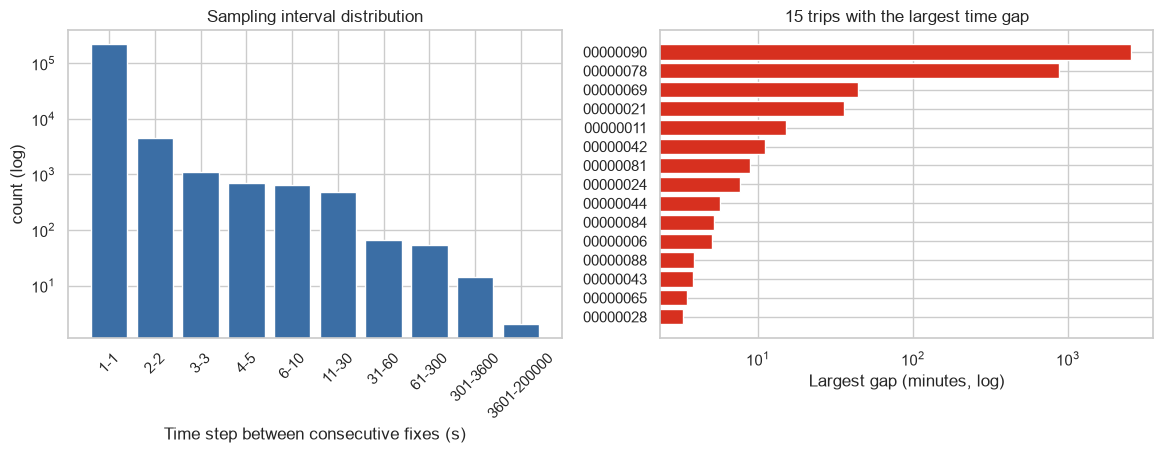

,partition,trip_id,n_points,duration_min,gaps_gt10s,gaps_gt60s,max_gap_s,pct_dt_1s
72,train,00000090,536,2567.2,6,1,153064.0,58.1
61,train,00000078,2909,963.9,25,1,52810.0,75.5
55,train,00000069,2067,92.6,2,2,2658.0,98.9
16,train,00000021,15783,310.1,2,2,2161.0,100.0
8,train,00000011,2828,62.2,1,1,909.0,100.0
34,train,00000042,7739,206.3,37,17,670.0,99.0
64,train,00000081,3224,141.4,86,15,536.0,72.0
18,train,00000024,801,25.7,2,2,458.0,97.1
36,train,00000044,546,16.3,2,1,341.0,90.1
67,train,00000084,16031,275.4,4,2,312.0,99.7


In [9]:
print(f"Timestamps strictly increasing in every trip: {(inv.non_increasing_t + inv.duplicate_t).sum() == 0}")
print(f"Share of 1-second steps over all trips: {100 * (dts.dt == 1).mean():.2f}%")
print(f"Trips with at least one gap > 10 s: {(inv.gaps_gt10s > 0).sum()} / {len(inv)};  > 60 s: {(inv.gaps_gt60s > 0).sum()}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bins = [0.5, 1.5, 2.5, 3.5, 5.5, 10.5, 30.5, 60.5, 300.5, 3600.5, 2e5]
cnt = pd.cut(dts.dt, bins).value_counts(sort=False)
axes[0].bar([f"{int(np.ceil(a))}-{int(b)}" for a, b in zip(bins[:-1], bins[1:])], cnt.values, color="#3b6ea5")
axes[0].set_yscale("log"); axes[0].set_xlabel("Time step between consecutive fixes (s)"); axes[0].set_ylabel("count (log)")
axes[0].tick_params(axis="x", rotation=45); axes[0].set_title("Sampling interval distribution")
o = inv.sort_values("max_gap_s", ascending=False).head(15)
axes[1].barh(o.trip_id, o.max_gap_s / 60, color="#d7301f"); axes[1].set_xscale("log"); axes[1].invert_yaxis()
axes[1].set_xlabel("Largest gap (minutes, log)"); axes[1].set_title("15 trips with the largest time gap")
savefig("03_sampling_gaps"); plt.show()
inv.sort_values("max_gap_s", ascending=False)[["partition", "trip_id", "n_points", "duration_min", "gaps_gt10s", "gaps_gt60s", "max_gap_s", "pct_dt_1s"]].head(10).round(1)

## 5. Geographic extent
**Partitions:** train + student_test.

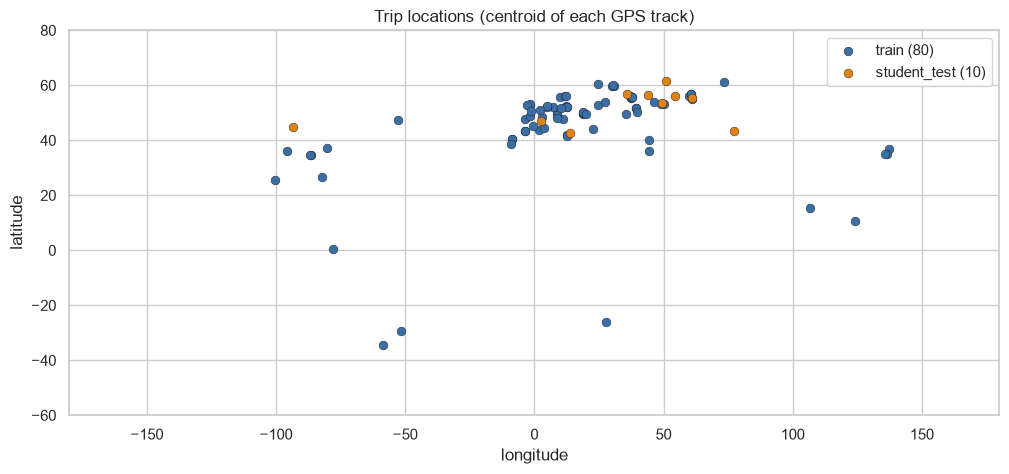

UTM zones used: 25 | latitude range -34.6 to 61.7


,bbox_w_km,bbox_h_km,path_km,duration_min
count,90.0,90.0,90.0,90.0
mean,13.6,11.6,36.1,87.9
std,15.9,14.1,33.5,287.3
min,0.9,0.9,5.6,4.4
25%,3.3,3.3,12.6,18.9
50%,6.8,5.3,23.3,28.5
75%,16.6,13.7,48.7,60.3
max,70.9,75.1,169.0,2567.2


In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
for part, c in [(TRAIN, "#3b6ea5"), (STUDENT_TEST, "#e08214")]:
    s = inv[inv.partition == part]
    ax.scatter(s.lon_c, s.lat_c, s=40, c=c, label=f"{part} ({len(s)})", edgecolor="k", lw=.3)
ax.set_xlim(-180, 180); ax.set_ylim(-60, 80); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Trip locations (centroid of each GPS track)"); ax.legend()
savefig("04_trip_locations"); plt.show()

world = folium.Map(location=[30, 20], zoom_start=2, tiles="OpenStreetMap")
for part, c in [(TRAIN, "blue"), (STUDENT_TEST, "orange")]:
    fg = folium.FeatureGroup(name=f"{part} trips")
    for r in inv[inv.partition == part].itertuples():
        folium.CircleMarker([r.lat_c, r.lon_c], radius=5, color=c, fill=True,
                            tooltip=f"{r.trip_id} ({part}) - {r.n_points} pts, {r.path_km:.1f} km").add_to(fg)
    fg.add_to(world)
folium.LayerControl(collapsed=False).add_to(world)
world.save(MAPS_DIR / "eda_trip_overview.html")
print("UTM zones used:", inv.crs.nunique(), "| latitude range %.1f to %.1f" % (inv.lat_c.min(), inv.lat_c.max()))
inv[["bbox_w_km", "bbox_h_km", "path_km", "duration_min"]].describe().round(1)

The trips are spread across **multiple continents and UTM zones**, so there is no single "local" projection.
Each trip is projected to its **own UTM zone** (`geo.project_trip`). We checked it against exact WGS84
geodesic distances: the error is ≤ 0.04%, while haversine (spherical Earth) is off by ~0.3%.

## 6. Trajectory patterns
**Partition:** train.

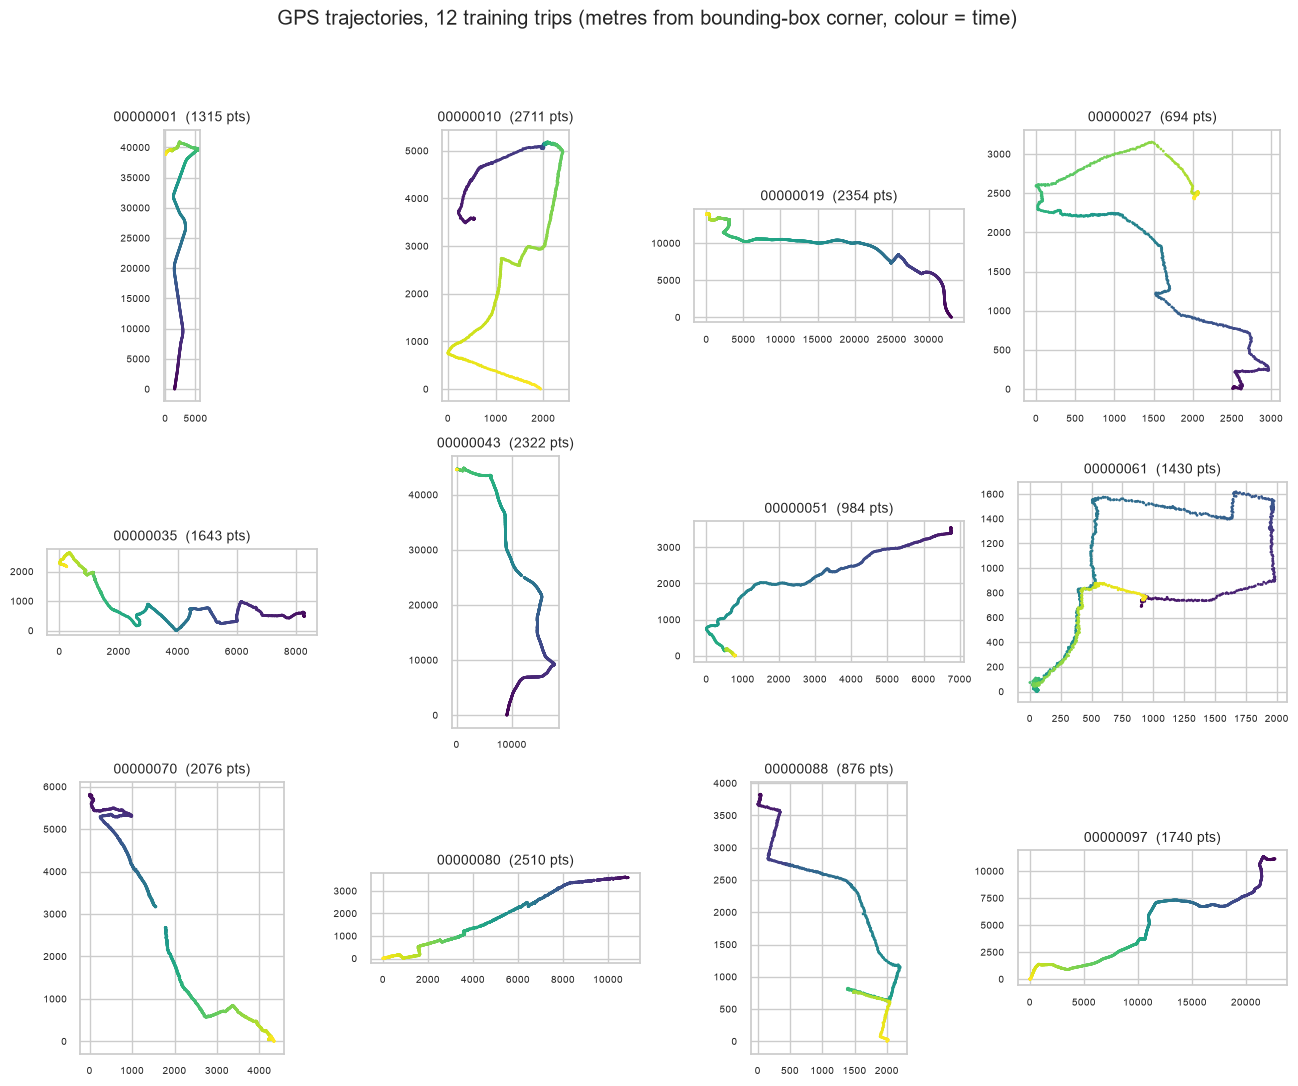

In [11]:
sample_ids = list_trips(TRAIN)[::7][:12]
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, tid in zip(axes.flat, sample_ids):
    tr = project_trip(load_trip(tid, TRAIN)).track
    sc = ax.scatter(tr.x - tr.x.min(), tr.y - tr.y.min(), c=tr.t - tr.t.min(), s=1, cmap="viridis")
    ax.set_aspect("equal"); ax.set_title(f"{tid}  ({len(tr)} pts)", fontsize=10); ax.tick_params(labelsize=7)
fig.suptitle("GPS trajectories, 12 training trips (metres from bounding-box corner, colour = time)")
savefig("05_trajectory_samples"); plt.show()

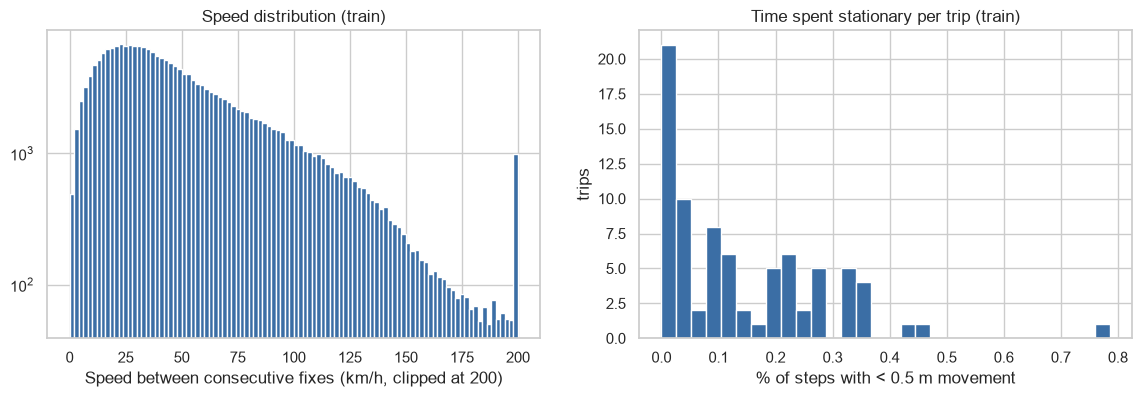

Speed percentiles km/h (train): {50: np.float64(40.0), 90: np.float64(98.8), 99: np.float64(167.0), 99.9: np.float64(241.7)}


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
s = speeds[speeds.partition == TRAIN].speed_kmh
axes[0].hist(s.clip(upper=200), bins=100, color="#3b6ea5"); axes[0].set_yscale("log")
axes[0].set_xlabel("Speed between consecutive fixes (km/h, clipped at 200)"); axes[0].set_title("Speed distribution (train)")
axes[1].hist(inv[inv.partition == TRAIN].stationary_pct, bins=30, color="#3b6ea5")
axes[1].set_xlabel("% of steps with < 0.5 m movement"); axes[1].set_ylabel("trips"); axes[1].set_title("Time spent stationary per trip (train)")
savefig("06_speed_stationary"); plt.show()
print(f"Speed percentiles km/h (train): " + str({q: round(s.quantile(q / 100), 1) for q in (50, 90, 99, 99.9)}))

## 7. Road network size and connectivity
**Partitions:** train + student_test.

Each trip comes with its **own** road network (a directed graph: nodes = points, arcs = directed road segments).
Connectivity is measured with weakly connected components (ignoring direction) and strongly connected
components (every node reachable from every other node following arc directions).

In [13]:
net_cols = ["n_nodes", "n_arcs", "isolated_nodes", "self_loops", "duplicate_arcs", "zero_length_arcs", "two_way_pct",
            "median_arc_m", "n_weak_components", "largest_wcc_pct", "n_strong_components", "largest_scc_pct"]
inv[net_cols].to_csv(EDA_DIR / "network_stats_columns_reference.csv", index=False)
net = inv.groupby("partition")[net_cols].median().T.round(1)
net.columns = [f"median ({c})" for c in net.columns]
net["min (all)"] = inv[net_cols].min().round(1); net["max (all)"] = inv[net_cols].max().round(1)
net.to_csv(EDA_DIR / "network_summary.csv")
net

,median (student_test),median (train),min (all),max (all)
n_nodes,6596.5,9608.0,299.0,155003.0
n_arcs,13145.0,19526.5,649.0,307392.0
isolated_nodes,0.0,0.0,0.0,0.0
self_loops,0.0,0.0,0.0,8.0
duplicate_arcs,3.5,2.0,0.0,322.0
zero_length_arcs,0.0,0.0,0.0,14.0
two_way_pct,93.3,95.1,35.1,100.0
median_arc_m,31.9,24.6,6.8,85.1
n_weak_components,11.0,20.0,1.0,421.0
largest_wcc_pct,97.1,98.1,69.3,100.0


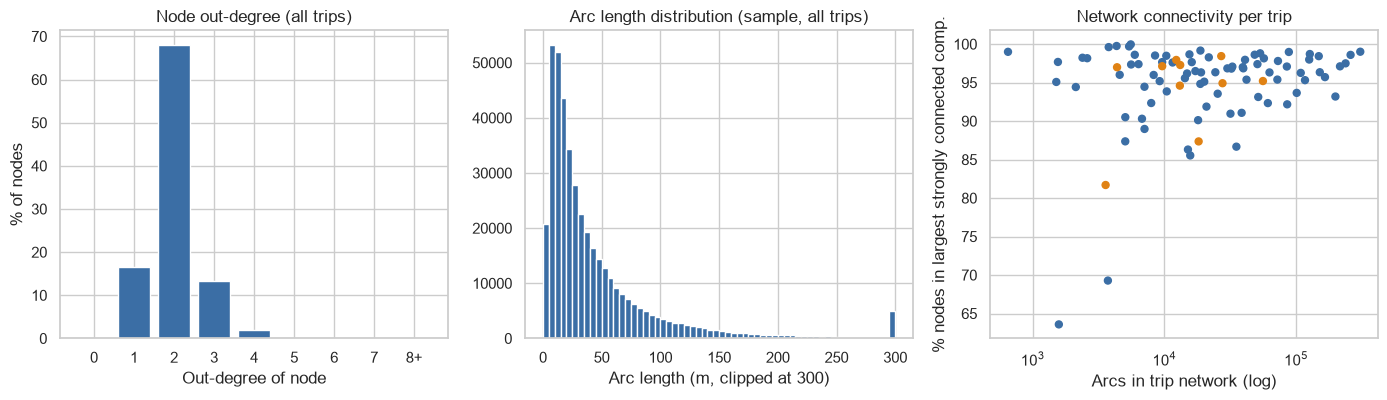

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
deg = np.concatenate(out_degs)
vals, counts = np.unique(np.minimum(deg, 8), return_counts=True)
axes[0].bar([str(v) if v < 8 else "8+" for v in vals], counts / counts.sum() * 100, color="#3b6ea5")
axes[0].set_xlabel("Out-degree of node"); axes[0].set_ylabel("% of nodes"); axes[0].set_title("Node out-degree (all trips)")
al = pd.concat(arc_lens)
axes[1].hist(al.clip(upper=300), bins=60, color="#3b6ea5"); axes[1].set_xlabel("Arc length (m, clipped at 300)")
axes[1].set_title("Arc length distribution (sample, all trips)")
axes[2].scatter(inv.n_arcs, inv.largest_scc_pct, c=np.where(inv.partition == TRAIN, "#3b6ea5", "#e08214"), s=25)
axes[2].set_xscale("log"); axes[2].set_xlabel("Arcs in trip network (log)"); axes[2].set_ylabel("% nodes in largest strongly connected comp.")
axes[2].set_title("Network connectivity per trip")
savefig("07_network_structure"); plt.show()

## 8. Reference routes
**Partitions:** train + student_test.

The `.route` file is an ordered list of arc ids. For a valid driven path, each arc should end where the next one
begins (`arcs.v[route[i]] == arcs.u[route[i+1]]`).

In [15]:
rt = inv[["partition", "trip_id", "n_route", "route_unique_arcs", "route_repeated_arcs", "route_km",
          "route_connected_pct", "route_breaks", "route_in_largest_scc_pct"]]
rt.to_csv(EDA_DIR / "route_stats.csv", index=False)
print(f"Trips whose route is fully connected: {(rt.route_breaks == 0).sum()} / {len(rt)}")
print(f"Trips that drive at least one arc twice: {(rt.route_repeated_arcs > 0).sum()}")
rt.describe().round(1)

Trips whose route is fully connected: 79 / 90
Trips that drive at least one arc twice: 10


,n_route,route_unique_arcs,route_repeated_arcs,route_km,route_connected_pct,route_breaks,route_in_largest_scc_pct
count,90.0,90.0,90.0,90.0,90.0,90.0,90.0
mean,386.8,383.2,3.6,27.5,99.9,0.2,99.0
std,359.2,351.9,27.0,25.2,0.2,0.5,5.8
min,59.0,59.0,0.0,5.0,98.1,0.0,46.7
25%,166.8,165.2,0.0,9.0,100.0,0.0,100.0
50%,272.5,272.5,0.0,14.3,100.0,0.0,100.0
75%,464.2,455.5,0.0,39.8,100.0,0.0,100.0
max,2266.0,2252.0,255.0,94.3,100.0,3.0,100.0


In [16]:
rt[rt.route_breaks > 0].sort_values("route_breaks", ascending=False).round(1)

,partition,trip_id,n_route,route_unique_arcs,route_repeated_arcs,route_km,route_connected_pct,route_breaks,route_in_largest_scc_pct
14,train,00000019,545,545,0,42.8,99.4,3,97.6
60,train,00000075,108,106,2,6.4,98.1,2,100.0
1,train,00000002,262,262,0,8.0,99.6,1,100.0
26,train,00000033,169,169,0,6.4,99.4,1,100.0
33,train,00000041,340,340,0,12.6,99.7,1,100.0
34,train,00000042,1440,1440,0,80.3,99.9,1,100.0
55,train,00000069,467,438,29,19.4,99.8,1,100.0
63,train,00000080,139,139,0,12.4,99.3,1,100.0
69,train,00000086,671,669,2,78.3,99.9,1,93.0
71,train,00000089,265,265,0,11.3,99.6,1,100.0


## 9. GPS observations vs. the reference route
**Partitions:** train + student_test (the histograms use train only).

The route does not say which GPS point belongs to which arc, so we align them with a monotone
dynamic programme (`labels.align_route`): each point is matched to a route arc, and the matching can only stay
or move forward along the route. The distance from each point to its aligned arc shows how noisy the GPS is and
where the reference route does not describe the track.

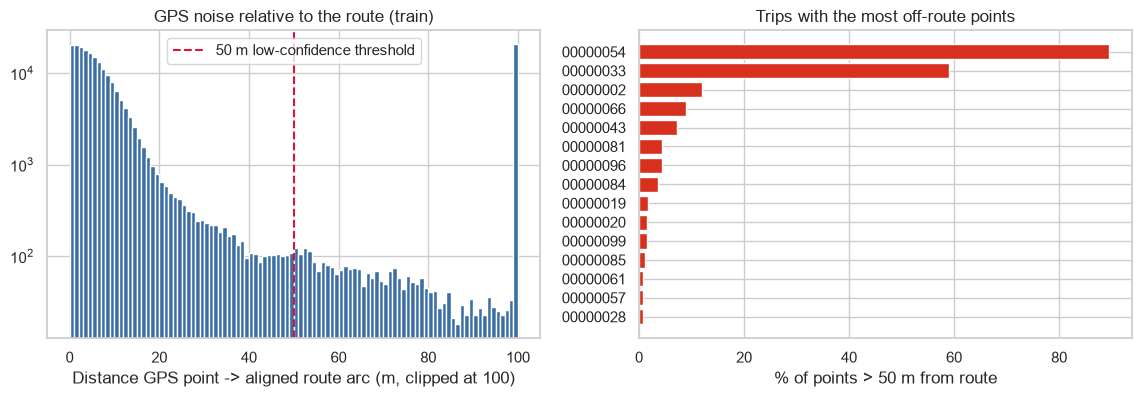

Distance percentiles (train, m): {50: np.float64(5.7), 90: np.float64(89.4), 95: np.float64(142.1), 99: np.float64(205.8)}
Points > 50 m from route: 11.16% of train points
Points whose nearest arc is tied with its reverse twin (two-way street): 63.9% (mean over trips)


In [17]:
ld = label_d[label_d.partition == TRAIN].label_dist_m
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(ld.clip(upper=100), bins=100, color="#3b6ea5"); axes[0].set_yscale("log")
axes[0].axvline(50, color="crimson", ls="--", label="50 m low-confidence threshold"); axes[0].legend()
axes[0].set_xlabel("Distance GPS point -> aligned route arc (m, clipped at 100)"); axes[0].set_title("GPS noise relative to the route (train)")
o = inv.sort_values("low_conf_pct", ascending=False).head(15)
axes[1].barh(o.trip_id, o.low_conf_pct, color="#d7301f"); axes[1].invert_yaxis()
axes[1].set_xlabel("% of points > 50 m from route"); axes[1].set_title("Trips with the most off-route points")
savefig("08_gps_vs_route"); plt.show()
print("Distance percentiles (train, m):", {q: round(ld.quantile(q / 100), 1) for q in (50, 90, 95, 99)})
print(f"Points > 50 m from route: {100 * (ld > 50).mean():.2f}% of train points")
print(f"Points whose nearest arc is tied with its reverse twin (two-way street): {inv.nearest_tie_pct.mean():.1f}% (mean over trips)")

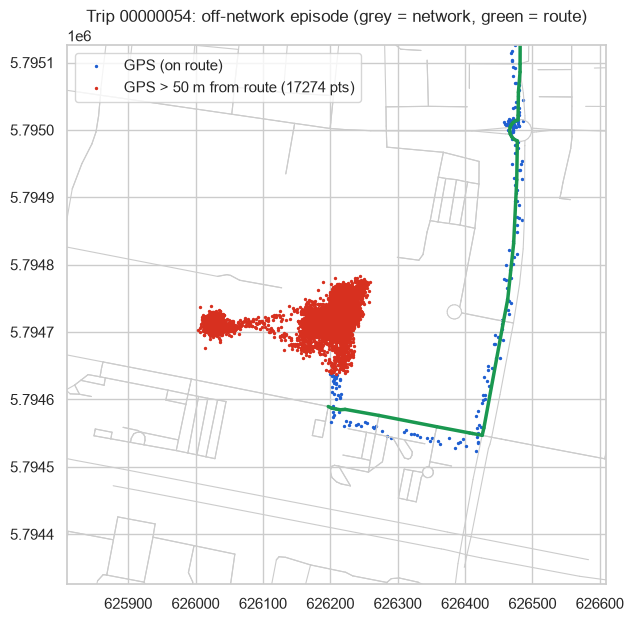

Off-route points: 17274 in 29 episodes; longest episode: 15584 points (4.3 h)
Longest episode starts and ends 6 m apart; median apparent speed 7.1 m/s; no mapped road nearby


In [18]:
# Why some points are far from the route: the off-network episode in train trip 00000054
trip = project_trip(load_trip("00000054", TRAIN, with_route=True)); g = arc_table(trip); tr = trip.track
lab = align_route(trip); far = lab.low_conf.to_numpy()
cx, cy = tr.x[far].median(), tr.y[far].median(); R = 400
fig, ax = plt.subplots(figsize=(7, 7))
near = g[(abs(g.ax - cx) < R) & (abs(g.ay - cy) < R)]
for a in near.itertuples(): ax.plot([a.ax, a.bx], [a.ay, a.by], color="0.8", lw=.8)
for a in g.loc[trip.route].itertuples(): ax.plot([a.ax, a.bx], [a.ay, a.by], color="#1a9850", lw=2.5)
ax.scatter(tr.x[~far], tr.y[~far], s=2, c="#1f5fd1", label="GPS (on route)")
ax.scatter(tr.x[far], tr.y[far], s=2, c="#d7301f", label=f"GPS > 50 m from route ({far.sum()} pts)")
ax.set_xlim(cx - R, cx + R); ax.set_ylim(cy - R, cy + R); ax.set_aspect("equal"); ax.legend(loc="upper left")
ax.set_title("Trip 00000054: off-network episode (grey = network, green = route)")
savefig("09_off_network_trip54"); plt.show()
idx = np.where(far)[0]
runs = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)
run = max(runs, key=len)
step = np.r_[0, np.hypot(np.diff(tr.x), np.diff(tr.y))]
print(f"Off-route points: {far.sum()} in {len(runs)} episodes; longest episode: {len(run)} points "
      f"({(tr.t.iloc[run[-1]] - tr.t.iloc[run[0]]) / 3600:.1f} h)")
print(f"Longest episode starts and ends {np.hypot(tr.x.iloc[run[-1]] - tr.x.iloc[run[0]], tr.y.iloc[run[-1]] - tr.y.iloc[run[0]]):.0f} m apart; "
      f"median apparent speed {np.median(step[run]):.1f} m/s; no mapped road nearby")

## 10. Anomalous trips
**Partitions:** train + student_test.

Rule-based flags. The thresholds are fixed by physical reasoning, not tuned on any partition.

In [19]:
flags = pd.DataFrame({
    "trip_id": inv.trip_id, "partition": inv.partition,
    "gap_over_1h": inv.max_gap_s > 3600,
    "gaps_over_60s": inv.gaps_gt60s > 0,
    "implausible_jumps": inv.jumps > 0,
    "mostly_off_route(>5%)": inv.low_conf_pct > 5,
    "route_breaks": inv.route_breaks > 0,
    "non_integer_t": inv.non_integer_t > 0,
    "stationary>30%": inv.stationary_pct > 30,
})
flags["n_flags"] = flags.iloc[:, 2:].sum(axis=1)
flags.to_csv(EDA_DIR / "anomaly_flags.csv", index=False)
print("Trips per flag:"); print(flags.iloc[:, 2:-1].sum().to_string())
flags[flags.n_flags >= 2].sort_values("n_flags", ascending=False)

Trips per flag:
gap_over_1h               2
gaps_over_60s            23
implausible_jumps        11
mostly_off_route(>5%)     5
route_breaks             11
non_integer_t             3
stationary>30%            0


,trip_id,partition,gap_over_1h,gaps_over_60s,implausible_jumps,mostly_off_route(>5%),route_breaks,non_integer_t,stationary>30%,n_flags
1,00000002,train,False,True,False,True,True,True,False,4
26,00000033,train,False,False,True,True,True,False,False,3
35,00000043,train,False,True,True,True,False,False,False,3
33,00000041,train,False,True,False,False,True,False,False,2
34,00000042,train,False,True,False,False,True,False,False,2
44,00000054,train,False,True,False,True,False,False,False,2
55,00000069,train,False,True,False,False,True,False,False,2
61,00000078,train,True,True,False,False,False,False,False,2
71,00000089,train,False,True,False,False,True,False,False,2
72,00000090,train,True,True,False,False,False,False,False,2


## 11. Folium maps
**Partition:** train (reference route is shown, which is allowed for training data).

Layers: GPS observations (blue), nearby road network (grey), reference route (green), start/end markers.
Each layer can be toggled in the layer control. The same `viz.trip_map` function draws the predicted route later.

In [20]:
trip = load_trip("00000001", TRAIN, with_route=True)
m1 = trip_map(trip, reference_route=trip.route, title="Trip 00000001 (train): GPS vs reference route")
m1.save(MAPS_DIR / "eda_trip_00000001.html")

trip = load_trip("00000054", TRAIN, with_route=True)
trip_map(trip, reference_route=trip.route, title="Trip 00000054 (train): off-network episode").save(MAPS_DIR / "eda_trip_00000054.html")

trip = load_trip("00000090", TRAIN, with_route=True)
trip_map(trip, reference_route=trip.route, title="Trip 00000090 (train): 42 h gap").save(MAPS_DIR / "eda_trip_00000090.html")
print("saved:", sorted(p.name for p in MAPS_DIR.glob("eda_*.html")))
m1

saved: ['eda_trip_00000001.html', 'eda_trip_00000054.html', 'eda_trip_00000090.html', 'eda_trip_overview.html']


## 12. Key findings and decisions
**Partitions:** train + student_test. The same list, with evidence and decisions, is in `docs/data_quality.md`.

| # | Finding | Decision |
|---|---------|----------|
| 1 | 80 train + 10 student_test trips, all 4 files present for every trip. 227,577 GPS points (208,417 train / 19,160 student_test), 90 MB raw. | Loader reads by partition folder; trip ids are unique across partitions. |
| 2 | No NaNs, no impossible coordinates, timestamps strictly increasing in all trips. 3 trips (`02`, `71`, `97`) have fractional timestamps. | No imputation needed. Timestamps are treated as continuous seconds. |
| 3 | Nominally 1 Hz (96.7% of steps are 1 s), but 42/90 trips have gaps > 10 s and 23 have gaps > 60 s. Extremes: trip `90` has a 42.5 h gap (99.6% of its duration has no fix), trip `78` has 14.7 h. | The track is split into **segments at gaps > 10 s**. Smoothing, neighbour features and HMM transitions never cross a gap. |
| 4 | 151 implausible jumps (> 252 km/h between fixes) in 11 trips, concentrated in trips `13` (95) and `32` (43). | Points are kept (dropping them would leave holes). Neighbourhood features and HMM transitions down-weight isolated jumps. |
| 5 | Trips span 25 UTM zones (latitude −34.6 to 61.7). | Each trip is projected to **its own UTM zone**: ≤ 0.04% error vs exact geodesic. Never use degrees as distances. |
| 6 | Each trip has its **own** directed network: 649 to 307,392 arcs. About 95% of arcs have a reverse twin (two-way streets). No isolated nodes, but many small strongly connected components (median 127 in train) from clipping at the network boundary. 1,903 duplicate arcs (same u→v), 106 zero-length arcs, 24 self-loops. | Key arcs by `(trip_id, arc_id)`. Use a spatial index for candidate search. The HMM must give unreachable transitions a finite penalty, not −∞. |
| 7 | Reference routes: 59 to 2,266 arcs. 79/90 are fully connected; 11 trips have 1–3 breaks between consecutive arcs. 10 trips drive some arc more than once. | The reference is treated as **reference, not perfect ground truth**. Labels are aligned by route *position* (monotone alignment), so repeated arcs are handled. |
| 8 | GPS points are a median 5.7 m from the aligned route arc, but 11.2% of training points are > 50 m away. Most come from **off-network episodes**: in trip `54` the vehicle spends 4.3 h (15,584 points) inside a ~1 km² area with no mapped road, ending within 6 m of where it started. Trip `33` is similar. | These points are flagged `low_conf`. Models are trained on confident points, and metrics are reported both on confident points and on all points. |
| 9 | For about 64% of points (mean over trips), the nearest arc is tied with its reverse twin (same road, opposite direction). | Distance alone is a coin flip, so **heading vs arc bearing** is a core feature. |
| 10 | student_test trips look like train trips (similar median points, network size, route length). | Student-test results should be representative of training CV. |